In [1]:
import pandas as pd
import numpy as np
import sys, os, pathlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
BASE_DIR = Path.cwd().parent

## Dataset pre-processing for classification work with IS
* merge 3 datasets. Drop duplicates
* ensure that 'censored' datapoints are handled appropriately 
* perform dataset splitting and create respective featurisations/embeddings
* save / prep for model training

In [2]:
# import datasets 
DATA_PATH = BASE_DIR / "01_DATASETS"
app = pd.read_csv(DATA_PATH / "APP2024_original.csv")
manner = pd.read_csv(DATA_PATH / "MANNER_IS.csv")
manner.rename(columns={"SMILES_dat": "SMILES"}, inplace=True)

quayle = pd.read_csv(DATA_PATH / "QU_IS.csv")

In [3]:
def add_canon_smiles(df, smiles_col="SMILES"):
    """
    Add a column with canonical SMILES to the dataframe.
    """
    from rdkit import Chem
    df["canonical_SMILES"] = df[smiles_col].apply(lambda x: Chem.MolToSmiles(Chem.MolFromSmiles(x), canonical=True))
    return df

for df in [app, manner, quayle]:
    df = add_canon_smiles(df)

In [4]:
# convert cencored data for quayle
QU_IS_data = quayle["Exp IS (J)"]
QU_IS_data = QU_IS_data.str.replace(r'^[<>]=?', '', regex=True).astype(float)
quayle["Exp IS (J)"] = QU_IS_data

quayle = quayle[["SMILES", "Exp IS (J)", "canonical_SMILES"]].copy()
quayle["Source"] = "QUAYLE"
quayle["Exp IS (J)"].isna().sum()

np.int64(0)

In [5]:
#import g constant
from scipy.constants import g

# clean app dataset
app_IS = app[app["prop"] == "log(h50) exp"].copy()
app_IS["Exp IS (J)"] = app_IS["val"].apply(lambda x: 2.5*g*(10**x)/100) # convert log(h50) to IS in J
app_IS = app_IS[["SMILES", "Exp IS (J)", "canonical_SMILES"]].copy()
app_IS["Source"] = "APPLETON"
app_IS["Exp IS (J)"].isna().sum()

np.int64(0)

In [6]:
# manner 
manner["Exp IS (J)"] = manner["logImpact_J"].apply(lambda x: 10**x)
manner = manner[["SMILES", "Exp IS (J)", "canonical_SMILES"]].copy()
manner["Source"] = "MARRS"
manner["Exp IS (J)"].isna().sum()

np.int64(0)

In [7]:
# Concatenate all datasets, while dropping duplicates based on canonical SMILES
combined_df = pd.concat([app_IS, manner, quayle], ignore_index=True)
original_length = combined_df.shape[0]
combined_df = combined_df.drop_duplicates(subset=['canonical_SMILES']).reset_index(drop=True)
print(f"Combined dataset length: {combined_df.shape[0]}")
print(f"Removed duplicates: {original_length - combined_df.shape[0]}")
print(f"Number of missing values in Exp IS (J): {combined_df['Exp IS (J)'].isna().sum()}")

Combined dataset length: 981
Removed duplicates: 1340
Number of missing values in Exp IS (J): 0


## Datalabels for classification

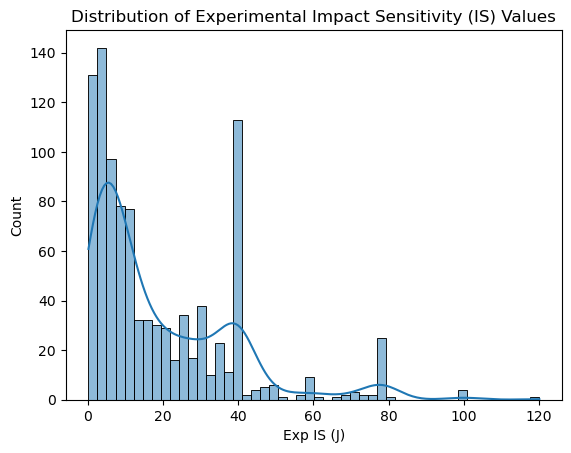

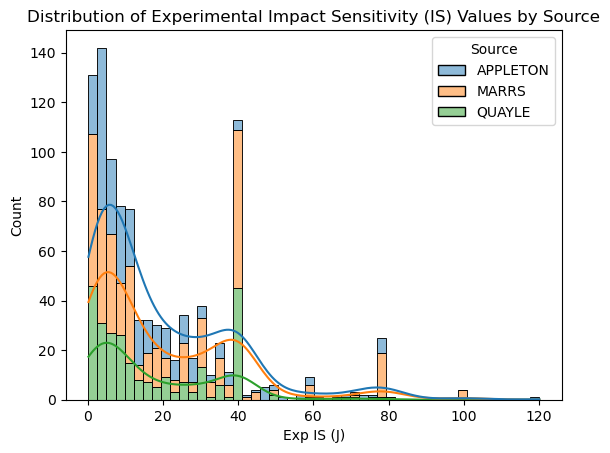

In [8]:
# get distribution of IS values 

sns.histplot(data=combined_df, x="Exp IS (J)", bins=50, kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values")
plt.show()

# separate by datasource
sns.histplot(data=combined_df, x="Exp IS (J)", bins=50, hue="Source", multiple="stack", kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values by Source")
plt.show() 

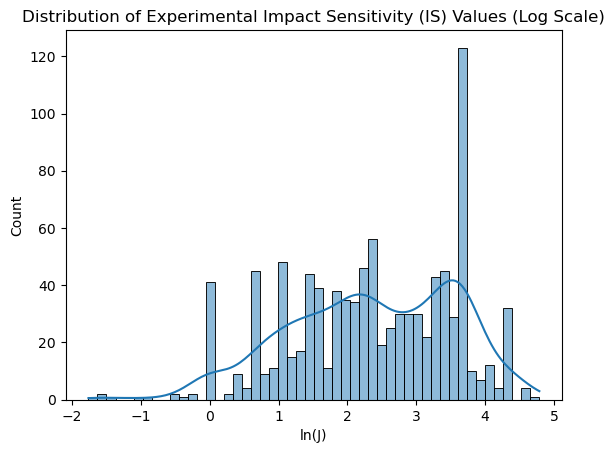

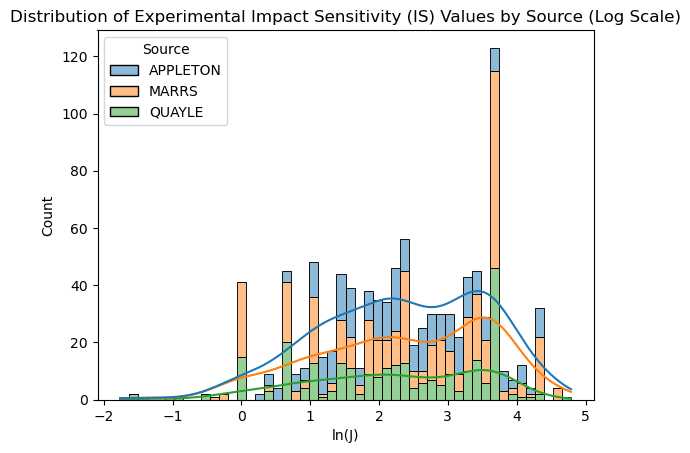

In [9]:
combined_df["ln(J)"] = np.log(combined_df["Exp IS (J)"])

# repeat both of the plots but with log scale on x-axis
sns.histplot(data=combined_df, x="ln(J)", bins=50, kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values (Log Scale)")
plt.show()  

sns.histplot(data=combined_df, x="ln(J)", bins=50, hue="Source", multiple="stack", kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values by Source (Log Scale)")
plt.show()

# Set data labels

Using the same cutoffs as in [the paper](https://pubs-rsc-org.eux.idm.oclc.org/dd/article/4/11/3260/312862/Understanding-impact-sensitivity-of-energetic)

In [10]:
# set binary classification threshold
threshold = 8 # J
combined_df["binary"] = (combined_df["Exp IS (J)"] > threshold).astype(int)

#count the number of samples in each class
class_counts = combined_df["binary"].value_counts()
print(f"Number of samples in class 0 (IS <= {threshold} J): {class_counts[0]}")
print(f"Number of samples in class 1 (IS > {threshold} J): {class_counts[1]}")
print(f"Number of missing values in binary classification: {combined_df['binary'].isna().sum()}")

Number of samples in class 0 (IS <= 8 J): 393
Number of samples in class 1 (IS > 8 J): 588
Number of missing values in binary classification: 0


In [11]:
# Tertiary classification based on thresholds
cutoffs = [6, 20]  # Define the cutoffs for low, medium, and high
combined_df["tertiary"] = pd.cut(combined_df["Exp IS (J)"], bins=[-np.inf] + cutoffs + [np.inf], labels=[0, 1, 2])

# count the number of samples in each tertiary class
tertiary_class_counts = combined_df["tertiary"].value_counts().sort_index()
print(f"Number of samples in class 0 (IS <= {cutoffs[0]} J): {tertiary_class_counts[0]}")
print(f"Number of samples in class 1 ({cutoffs[0]} J < IS <= {cutoffs[1]} J): {tertiary_class_counts[1]}")
print(f"Number of samples in class 2 (IS > {cutoffs[1]} J): {tertiary_class_counts[2]}")
print(f"Number of missing values in tertiary classification: {combined_df['tertiary'].isna().sum()}")

Number of samples in class 0 (IS <= 6 J): 324
Number of samples in class 1 (6 J < IS <= 20 J): 311
Number of samples in class 2 (IS > 20 J): 346
Number of missing values in tertiary classification: 0


In [12]:
# Quaternary classification based on thresholds
quaternary_cutoffs = [4, 10, 30]  # Define the cutoffs for low, medium, high, and very high
combined_df["quaternary"] = pd.cut(combined_df["Exp IS (J)"], bins=[-np.inf] + quaternary_cutoffs + [np.inf], labels=[0, 1, 2, 3])

# count the number of samples in each quaternary class
quaternary_class_counts = combined_df["quaternary"].value_counts().sort_index()
print(f"Number of samples in class 0 (IS <= {quaternary_cutoffs[0]} J): {quaternary_class_counts[0]}")
print(f"Number of samples in class 1 ({quaternary_cutoffs[0]} J < IS <= {quaternary_cutoffs[1]} J): {quaternary_class_counts[1]}")
print(f"Number of samples in class 2 ({quaternary_cutoffs[1]} J < IS <= {quaternary_cutoffs[2]} J): {quaternary_class_counts[2]}")
print(f"Number of samples in class 3 (IS > {quaternary_cutoffs[2]} J): {quaternary_class_counts[3]}")
print(f"Number of missing values in quaternary classification: {combined_df['quaternary'].isna().sum()}")

Number of samples in class 0 (IS <= 4 J): 236
Number of samples in class 1 (4 J < IS <= 10 J): 257
Number of samples in class 2 (10 J < IS <= 30 J): 255
Number of samples in class 3 (IS > 30 J): 233
Number of missing values in quaternary classification: 0


In [13]:
# Quinary classification based on thresholds
quinary_cutoffs = [3, 8, 18, 40]  # Define the cutoffs for five classes
combined_df["quinary"] = pd.cut(combined_df["Exp IS (J)"], bins=[-np.inf] + quinary_cutoffs + [np.inf], labels=[0, 1, 2, 3, 4])

# count the number of samples in each quinary class
quinary_class_counts = combined_df["quinary"].value_counts().sort_index()
print(f"Number of samples in class 0 (IS <= {quinary_cutoffs[0]} J): {quinary_class_counts[0]}")
print(f"Number of samples in class 1 ({quinary_cutoffs[0]} J < IS <= {quinary_cutoffs[1]} J): {quinary_class_counts[1]}")
print(f"Number of samples in class 2 ({quinary_cutoffs[1]} J < IS <= {quinary_cutoffs[2]} J): {quinary_class_counts[2]}")
print(f"Number of samples in class 3 ({quinary_cutoffs[2]} J < IS <= {quinary_cutoffs[3]} J): {quinary_class_counts[3]}")
print(f"Number of samples in class 4 (IS > {quinary_cutoffs[3]} J): {quinary_class_counts[4]}")

Number of samples in class 0 (IS <= 3 J): 180
Number of samples in class 1 (3 J < IS <= 8 J): 213
Number of samples in class 2 (8 J < IS <= 18 J): 208
Number of samples in class 3 (18 J < IS <= 40 J): 308
Number of samples in class 4 (IS > 40 J): 72


In [14]:
# Save the processed dataset to a CSV file
output_path = BASE_DIR / "08_CLASSIFICATION" / "01_DATASETS" / "combined_IS_dataset.csv"
combined_df.to_csv(output_path, index=False)

In [15]:
combined_df.columns

Index(['SMILES', 'Exp IS (J)', 'canonical_SMILES', 'Source', 'ln(J)', 'binary',
       'tertiary', 'quaternary', 'quinary'],
      dtype='object')

## Generate the datasplits 

In [16]:
# for each of the binary, tertiary, quaternary, and quinary classifications, generate a held-out test set (20% of the data)
# with matched class distributions. Use stratified sampling to ensure that the class distributions in the test set match those in the full dataset.
# Save the indexes of the test set as a numpy array to a file for later use in model evaluation.
# Naming convention: 01_DATASETS/[classification_type]/random_seed[seed]_split_test.npy 

from sklearn.model_selection import train_test_split

random_seed = 4
test_size = 0.20

classification_types = ["binary", "tertiary", "quaternary", "quinary"]

for classification_type in classification_types:
    class_column = f"{classification_type}"

    # Split dataframe indices while preserving class proportions
    _, test_indices = train_test_split(
        combined_df.index.to_numpy(),
        test_size=test_size,
        random_state=random_seed,
        stratify=combined_df[class_column],
    )

    output_dir = Path("01_DATASETS") / classification_type
    output_dir.mkdir(parents=True, exist_ok=True)

    output_file = output_dir / f"random_seed{random_seed}_split_test.npy"
    np.save(output_file, test_indices)

    print(f"Saved {len(test_indices)} indices to {output_file}")

Saved 197 indices to 01_DATASETS/binary/random_seed4_split_test.npy
Saved 197 indices to 01_DATASETS/tertiary/random_seed4_split_test.npy
Saved 197 indices to 01_DATASETS/quaternary/random_seed4_split_test.npy
Saved 197 indices to 01_DATASETS/quinary/random_seed4_split_test.npy
